# Tarea 2 · Parte 2 — Evaluación, comparación de modelos y extracción estructurada

**Estudiante:** Sandy Patricia Martinez Jara (@sandypmj)

**Reglas para métricas válidas:** la muestra de evaluación (10 documentos y 10 clips del corpus de la Parte 1) se sortea con semilla fija y se guarda en `datos/muestra_evaluacion.csv`. Las configuraciones de **todos** los modelos se fijan antes de calcular métricas y no se cambian después.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import utiles, voz
warnings.filterwarnings("ignore")

RAW = Path("datos/raw")
SEMILLA = 2026
docs = pd.read_pickle(RAW / "docs_ocr_respaldo.pkl")
aud = pd.read_pickle(RAW / "aud_respaldo.pkl")
aud["fuente_corta"] = aud["fuente"].str.split(" \\(").str[0]

MUESTRA = Path("datos/muestra_evaluacion.csv")
if MUESTRA.exists():
    muestra = pd.read_csv(MUESTRA)
else:
    cupos = {"impreso": 4, "foto": 3, "manuscrito": 3}     # los tres tipos
    m_doc = pd.concat([docs[docs["tipo"] == t].sample(n, random_state=SEMILLA) for t, n in cupos.items()])
    b = aud.sample(frac=1, random_state=SEMILLA)
    b["turno"] = b.groupby("fuente_corta").cumcount()      # alterna fuentes: entrevistas con ruido y lectura limpia
    m_aud = b.sort_values(["turno", "fuente_corta"]).head(10)
    muestra = pd.concat([pd.DataFrame({"id": m_doc["id"], "modalidad": "documento"}),
                         pd.DataFrame({"id": m_aud["id"], "modalidad": "audio"})])
    muestra.to_csv(MUESTRA, index=False)

ids_doc = muestra.query("modalidad == 'documento'")["id"].tolist()
ids_aud = muestra.query("modalidad == 'audio'")["id"].tolist()
ev_doc = docs.set_index("id").loc[ids_doc]
ev_aud = aud.set_index("id").loc[ids_aud]
display(ev_doc[["tipo", "descripcion"]])
display(ev_aud[["fuente_corta", "condicion", "duracion_seg"]])

,tipo,descripcion
id,,
doc_005,impreso,Billete de 100 intis (1987)
doc_006,impreso,Billete de 1000 intis (1988)
doc_004,impreso,Billete de 50 intis (1987)
doc_008,impreso,Billete de 10 000 intis (1988)
doc_017,foto,Captura propia: foto_03
doc_018,foto,Captura propia: foto_04
doc_016,foto,Captura propia: foto_02
doc_024,manuscrito,Captura propia: manuscrito_05
doc_020,manuscrito,Captura propia: manuscrito_01


,fuente_corta,condicion,duracion_seg
id,,,
clip_012,OpenSLR 73,lectura en estudio (limpio),66.2
clip_004,Wikimedia Commons,entrevista en exteriores / con ruido,89.7
clip_009,OpenSLR 73,lectura en estudio (limpio),60.3
clip_005,Wikimedia Commons,entrevista en exteriores / con ruido,9.9
clip_016,OpenSLR 73,lectura en estudio (limpio),61.4
clip_008,Wikimedia Commons,entrevista en exteriores / con ruido,80.9
clip_023,OpenSLR 73,lectura en estudio (limpio),63.4
clip_001,Wikimedia Commons,entrevista en exteriores / con ruido,79.7
clip_028,OpenSLR 73,lectura en estudio (limpio),64.8


## Modelos alternativos (configuración fijada antes de ver métricas)

- **Documentos: EasyOCR** (`es`, `paragraph=True`, CPU). Usa otra arquitectura (detector CRAFT + reconocedor CRNN) y se instala solo con pip.
- **Audio: Parakeet TDT 0.6B v3** (NVIDIA), vía `voz.Transcriptor`, con la misma segmentación por VAD. No es un modelo generativo, así que no "inventa" frases en el silencio. Si no carga en esta PC, se usa **Qwen3-ASR 0.6B** (decisión tomada de antemano).
- Las salidas y los tiempos se guardan en `datos/raw/alternativos.json`, caso por caso (si se corta, continúa donde quedó).

In [2]:
import easyocr

ALT = RAW / "alternativos.json"
alt = json.loads(ALT.read_text(encoding="utf-8")) if ALT.exists() else {}
def guardar():
    ALT.write_text(json.dumps(alt, ensure_ascii=False), encoding="utf-8")

# --- Documentos: EasyOCR ---
lector = easyocr.Reader(["es"], gpu=False)
for i, r in ev_doc.iterrows():
    k = f"easyocr|{i}"
    if k in alt:
        continue
    t0 = time.perf_counter()
    texto = " ".join(lector.readtext(r["ruta_original"], detail=0, paragraph=True))
    alt[k] = {"texto": texto, "segundos": round(time.perf_counter() - t0, 2), "modelo": "EasyOCR (es, paragraph=True, CPU)"}
    guardar()
    print(f"{k}: {alt[k]['segundos']} s")

# --- Audio: Parakeet (o Qwen3-ASR si Parakeet no carga) ---
asr_alt = None
for clave in ["parakeet-v3", "qwen3-asr-0.6b"]:
    try:
        asr_alt = voz.Transcriptor(clave)
        break
    except Exception as e:
        print(f"No se pudo cargar {clave}: {str(e)[:150]}")
nombre_alt = voz.MODELOS[asr_alt.clave]["nombre"]
print("ASR alternativo:", nombre_alt, "en", asr_alt.device)

for i, r in ev_aud.iterrows():
    k = f"asr_alt|{i}"
    if k in alt:
        continue
    x = voz.cargar_audio(r["archivo_audio"])
    t0 = time.perf_counter()
    texto = " ".join(s.texto for s in asr_alt.segmentos(x, idioma="es"))
    alt[k] = {"texto": texto, "segundos": round(time.perf_counter() - t0, 2), "modelo": nombre_alt}
    guardar()
    print(f"{k}: {alt[k]['segundos']} s")

print("\n✅ Modelos alternativos listos:", len(alt), "resultados guardados")

Using CPU. Note: This module is much faster with a GPU.


No se pudo cargar parakeet-v3: 
ParakeetFeatureExtractor requires the librosa library. But that was not found in your environment. You can install them with pip:
`pip install libros


Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

ASR alternativo: Qwen3-ASR 0.6B en cpu

✅ Modelos alternativos listos: 20 resultados guardados


---
# 1 · Referencias manuales (transcripción humana)

- Para cada caso de la muestra hay un archivo `datos/referencias/documentos/<id>.txt` o `datos/referencias/audios/<id>.txt` con la **transcripción hecha a mano por la estudiante**, mirando la imagen o escuchando el audio. Nunca se copiaron salidas de los modelos: si la referencia se parte de lo que dijo el modelo, el error medido sale artificialmente bajo.
- Las referencias se **seudonimizan con la misma función y la misma lista privada** que el corpus (`utiles.seudonimizar_con_conteo` + `reemplazos_privado.json`). Así la referencia y las salidas de los modelos usan las mismas marcas (`[PERSONA_1]`, `[DNI]`, …) y un nombre real no cuenta como error ni como acierto.
- Se guardan en la columna `texto_referencia` de `datos/documentos.csv` y `datos/transcripciones.csv` (solo las filas de la muestra; el resto queda vacío). La carpeta `datos/referencias/` no se sube a GitHub; lo publicado es la versión seudonimizada.
- Si falta una referencia o el archivo está vacío, la celda se detiene con un error que dice cuál.

In [3]:
REF = Path("datos/referencias")
REEMPLAZOS = json.loads((RAW / "reemplazos_privado.json").read_text(encoding="utf-8"))
# [PERSONA_3] es el entrevistador de clip_001 y solo aplica a audios: en los documentos "Jorge" es un personaje público o histórico
REEMPLAZOS_DOC = {k: v for k, v in REEMPLAZOS.items() if v != "[PERSONA_3]"}
doc_pub = pd.read_csv("datos/documentos.csv")        # corpus publicado (ya seudonimizado)
aud_pub = pd.read_csv("datos/transcripciones.csv")

def leer_referencias(ids, carpeta, reemplazos):
    """Lee las referencias manuales, las seudonimiza y anota cuáles faltan."""
    refs, faltan, conteo = {}, [], {}
    for i in ids:
        ruta = REF / carpeta / f"{i}.txt"
        texto = ruta.read_text(encoding="utf-8-sig").strip() if ruta.exists() else ""
        if not texto:
            faltan.append(ruta.as_posix())
            continue
        refs[i], c = utiles.seudonimizar_con_conteo(texto, reemplazos)
        for clase, n in c.items():
            conteo[clase] = conteo.get(clase, 0) + n
    return refs, faltan, conteo

ref_doc, faltan_doc, conteo_doc = leer_referencias(ids_doc, "documentos", REEMPLAZOS_DOC)
ref_aud, faltan_aud, conteo_aud = leer_referencias(ids_aud, "audios", REEMPLAZOS)
faltan = faltan_doc + faltan_aud
if faltan:
    raise FileNotFoundError(f"Faltan {len(faltan)} de 20 referencias manuales (no existen o están vacías):\n  "
                            + "\n  ".join(faltan))

doc_pub["texto_referencia"] = doc_pub["id"].map(ref_doc)
aud_pub["texto_referencia"] = aud_pub["id"].map(ref_aud)
doc_pub.to_csv("datos/documentos.csv", index=False)
aud_pub.to_csv("datos/transcripciones.csv", index=False)

print("Reemplazos hechos en las referencias:", {"documentos": conteo_doc, "audios": conteo_aud})
pd.DataFrame({
    "id": ids_doc + ids_aud,
    "modalidad": ["documento"] * len(ids_doc) + ["audio"] * len(ids_aud),
    "caracteres": [len(ref_doc[i]) for i in ids_doc] + [len(ref_aud[i]) for i in ids_aud],
    "palabras": [len(ref_doc[i].split()) for i in ids_doc] + [len(utiles.quitar_marcas(ref_aud[i]).split()) for i in ids_aud],
})

Reemplazos hechos en las referencias: {'documentos': {'DNI': 1}, 'audios': {'NOMBRE': 12}}


,id,modalidad,caracteres,palabras
0,doc_005,documento,132,22
1,doc_006,documento,135,22
2,doc_004,documento,135,22
3,doc_008,documento,156,25
4,doc_017,documento,545,75
5,doc_018,documento,1015,152
6,doc_016,documento,2489,427
7,doc_024,documento,1084,155
8,doc_020,documento,262,43
9,doc_025,documento,1165,158


---
# 2 · Línea base vs modelo alternativo

| Modalidad | Línea base (Parte 1) | Alternativo | Métrica |
|---|---|---|---|
| Documentos | PaddleOCR 3.7.0 sin ajuste | EasyOCR (`es`, `paragraph=True`) | **CER**: errores de carácter / caracteres de la referencia |
| Audio | faster-whisper `small` en CPU + VAD | Qwen3-ASR 0.6B (plan B fijado de antemano) | **WER**: errores de palabra / palabras de la referencia |

**Cómo se compara con justicia**

- Referencia y salida pasan por la **misma normalización** `voz.normalizar` (minúsculas, sin puntuación ni espacios repetidos; las tildes se quedan, porque una tilde mal puesta sí es un error de lectura).
- En audio se quitan las marcas `[HABLANTE_n]` con `utiles.quitar_marcas`: no son palabras habladas.
- Las salidas del alternativo se seudonimizan igual que la línea base, porque `alternativos.json` guarda el texto crudo.
- **Métrica global**: errores totales / longitud total de todas las referencias juntas (los casos largos pesan más). **Promedio por caso**: media de las métricas de cada caso (cada caso pesa igual). Se reportan las dos porque pueden contar historias distintas.
- **Latencia**: en documentos, segundos por página (cada documento es una imagen). En audio, **RTF** = segundos de proceso / duración del audio; RTF < 1 es más rápido que el tiempo real. Todos los modelos corrieron en la misma PC y en CPU.

In [4]:
ALT = RAW / "alternativos.json"
alt = json.loads(ALT.read_text(encoding="utf-8"))
corto = lambda modelo: modelo.split(" (")[0]          # "PaddleOCR 3.7.0 (lang=es, …)" → "PaddleOCR 3.7.0"
seudo = lambda texto, reemplazos=REEMPLAZOS: utiles.seudonimizar_con_conteo(texto, reemplazos)[0]

def caso(id_, modalidad, grupo, modelo, rol, hipotesis, referencia, segundos, duracion=None):
    """Una fila de resultados: normaliza los dos textos igual y calcula CER (documentos) o WER (audio)."""
    hip = voz.normalizar(utiles.quitar_marcas(hipotesis if isinstance(hipotesis, str) else ""))
    ref = voz.normalizar(utiles.quitar_marcas(referencia))
    metrica = "CER" if modalidad == "documento" else "WER"
    valor = (voz.cer if metrica == "CER" else voz.wer)([ref], [hip])
    return dict(id=id_, modalidad=modalidad, grupo=grupo, modelo=modelo, rol=rol, metrica=metrica,
                valor=round(valor, 4), segundos=float(segundos),
                rtf=round(float(segundos) / duracion, 3) if duracion else np.nan,
                hipotesis=hip, referencia=ref)

filas = []
for i, r in doc_pub.set_index("id").loc[ids_doc].iterrows():
    a = alt[f"easyocr|{i}"]
    filas += [caso(i, "documento", r["tipo"], corto(r["modelo_ocr"]), "línea base", r["texto_ocr"], ref_doc[i], r["segundos_proceso"]),
              caso(i, "documento", r["tipo"], corto(a["modelo"]), "alternativo", seudo(a["texto"], REEMPLAZOS_DOC), ref_doc[i], a["segundos"])]
for i, r in aud_pub.set_index("id").loc[ids_aud].iterrows():
    a = alt[f"asr_alt|{i}"]
    filas += [caso(i, "audio", r["condicion"], corto(r["modelo_asr"]), "línea base", r["texto_asr"], ref_aud[i], r["segundos_proceso"], r["duracion_seg"]),
              caso(i, "audio", r["condicion"], corto(a["modelo"]), "alternativo", seudo(a["texto"]), ref_aud[i], a["segundos"], r["duracion_seg"])]
res = pd.DataFrame(filas)

def error_global(g):
    """CER/WER de un grupo de casos como si fueran un solo texto largo."""
    f = voz.cer if g["metrica"].iat[0] == "CER" else voz.wer
    return f(g["referencia"].tolist(), g["hipotesis"].tolist())

metricas = pd.DataFrame([
    dict(modalidad=mod, modelo=modelo, rol=rol, metrica=g["metrica"].iat[0],
         valor_global=round(error_global(g), 4), promedio_por_caso=round(g["valor"].mean(), 4),
         segundos_medios=round(g["segundos"].mean(), 2),
         rtf_medio=round(g["rtf"].mean(), 3) if mod == "audio" else np.nan)
    for (mod, modelo, rol), g in res.groupby(["modalidad", "modelo", "rol"], sort=False)
])

res.to_csv("datos/resultados_evaluacion.csv", index=False)
metricas.to_csv("datos/metricas.csv", index=False)
display(metricas)
display(res.pivot_table(index=["modalidad", "grupo", "id"], columns="rol", values="valor").round(3))

,modalidad,modelo,rol,metrica,valor_global,promedio_por_caso,segundos_medios,rtf_medio
0,documento,PaddleOCR 3.7.0,línea base,CER,0.4250,0.3360,121.36,NaN
1,documento,EasyOCR,alternativo,CER,0.6101,0.4886,26.66,NaN
2,audio,faster-whisper 1.2.1 small,línea base,WER,0.1559,0.1239,19.63,0.291
3,audio,Qwen3-ASR 0.6B,alternativo,WER,0.1786,0.1544,50.65,0.756


rol                                                      alternativo  \
modalidad grupo                                id                      
audio     entrevista en exteriores / con ruido clip_001        0.268   
                                               clip_003        0.249   
                                               clip_004        0.248   
                                               clip_005        0.158   
                                               clip_008        0.178   
          lectura en estudio (limpio)          clip_009        0.091   
                                               clip_012        0.115   
                                               clip_016        0.084   
                                               clip_023        0.060   
                                               clip_028        0.094   
documento foto                                 doc_016         0.730   
                                               doc_017         0.575   
                                               doc_018         0.503   
          impreso                              doc_004         0.463   
                                               doc_005         0.356   
                                               doc_006         0.311   
                                               doc_008         0.353   
          manuscrito                           doc_020         0.342   
                                               doc_024         0.590   
                                               doc_025         0.665   

rol                                                      línea base  
modalidad grupo                                id                    
audio     entrevista en exteriores / con ruido clip_001       0.268  
                                               clip_003       0.221  
                                               clip_004       0.254  
                                               clip_005       0.105  
                                               clip_008       0.157  
          lectura en estudio (limpio)          clip_009       0.052  
                                               clip_012       0.023  
                                               clip_016       0.042  
                                               clip_023       0.050  
                                               clip_028       0.065  
documento foto                                 doc_016        0.686  
                                               doc_017        0.626  
                                               doc_018        0.164  
          impreso                              doc_004        0.276  
                                               doc_005        0.394  
                                               doc_006        0.370  
                                               doc_008        0.205  
          manuscrito                           doc_020        0.081  
                                               doc_024        0.254  
                                               doc_025        0.304

## 3 · ¿Dónde se equivocan más? Error por tipo de documento y condición del audio

Error global de cada grupo (todas sus referencias juntas). Las barras de documentos son CER y las de audio son WER: las dos son proporciones de error (0 = perfecto). El título se calcula con los datos, así que siempre dice lo que muestra el gráfico.

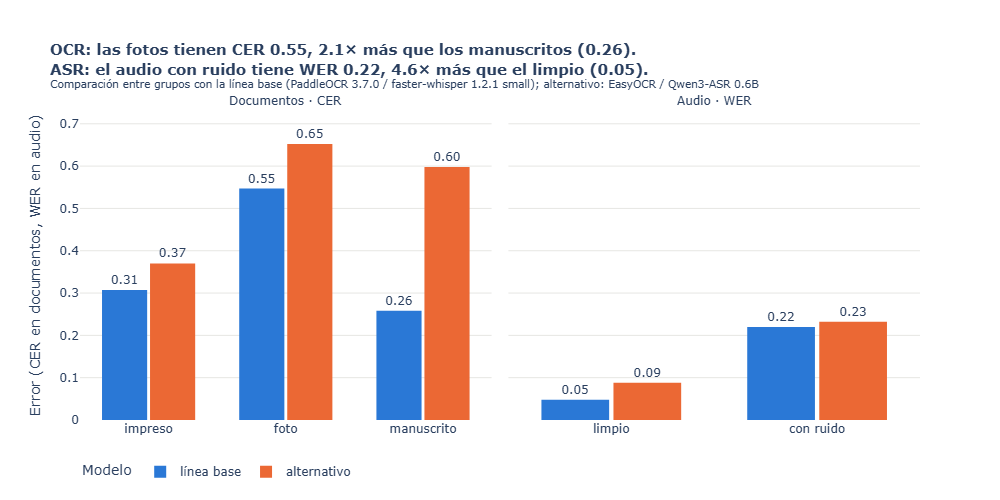

In [5]:
import plotly.express as px

COLORES = {"línea base": "#2a78d6", "alternativo": "#eb6834"}
CORTO = lambda g: "con ruido" if "ruido" in g else "limpio" if "limpio" in g else g
res["grupo_corto"] = res["grupo"].map(CORTO)

por_grupo = pd.DataFrame([
    dict(modalidad=mod, grupo=gr, rol=rol, modelo=modelo, error=round(error_global(g), 3), casos=len(g))
    for (mod, gr, rol, modelo), g in res.groupby(["modalidad", "grupo_corto", "rol", "modelo"], sort=False)
])

def contraste(mod):
    """Grupo más difícil vs más fácil para la línea base."""
    b = por_grupo.query("modalidad == @mod and rol == 'línea base'").sort_values("error")
    return b.iloc[-1], b.iloc[0]

(dd, fd), (da, fa) = contraste("documento"), contraste("audio")
veces = lambda a, b: f"{a / b:.1f}× más" if b > 0 else "frente a 0"
PLURAL = {"impreso": "los impresos", "foto": "las fotos", "manuscrito": "los manuscritos"}
modelos_de = lambda rol: " / ".join(res.loc[res["rol"] == rol, "modelo"].unique())
titulo = (f"<b>OCR: {PLURAL[dd.grupo]} tienen CER {dd.error:.2f}, {veces(dd.error, fd.error)} que {PLURAL[fd.grupo]} ({fd.error:.2f}).<br>"
          f"ASR: el audio {da.grupo} tiene WER {da.error:.2f}, {veces(da.error, fa.error)} que el {fa.grupo} ({fa.error:.2f}).</b><br>"
          f"<sup>Comparación entre grupos con la línea base ({modelos_de('línea base')}); alternativo: {modelos_de('alternativo')}</sup>")

fig = px.bar(por_grupo, x="grupo", y="error", color="rol", barmode="group", facet_col="modalidad",
             text="error", hover_data=["modelo", "casos"], color_discrete_map=COLORES,
             category_orders={"rol": ["línea base", "alternativo"], "modalidad": ["documento", "audio"]},
             labels={"error": "Error (CER en documentos, WER en audio)", "grupo": "", "rol": "Modelo"})
fig.update_xaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text="Documentos · CER" if "documento" in a.text else "Audio · WER"))
fig.update_traces(texttemplate="%{text:.2f}", textposition="outside", marker_line_width=0, cliponaxis=False)
fig.update_layout(title=dict(text=titulo, font_size=15), template="plotly_white", bargap=0.3, bargroupgap=0.06,
                  margin=dict(t=110), legend=dict(orientation="h", y=-0.12, x=0))
fig.update_yaxes(gridcolor="#e6e6e3", zeroline=False)
utiles.mostrar(fig)

## 4 · Casos difíciles: manuscritos y audio con ruido

Se compara el subgrupo difícil contra el resto con el error global de cada uno. La columna `veces` dice cuántas veces más error tiene el caso difícil. Después se muestran **3 ejemplos concretos de errores**:

1. el manuscrito con más error de la línea base;
2. el clip con ruido con más error de la línea base;
3. el caso donde línea base y alternativo más se separan.

En cada ejemplo, `substitute` es una palabra leída como otra, `delete` una palabra que el modelo omitió e `insert` una palabra que el modelo agregó.

In [6]:
import jiwer

SUBGRUPOS = {"documento": ("manuscrito", "resto (impreso + foto)"), "audio": ("con ruido", "limpio")}
res["subgrupo"] = np.where(res["modalidad"] == "documento",
                           np.where(res["grupo"] == "manuscrito", *SUBGRUPOS["documento"]),
                           np.where(res["grupo_corto"] == "con ruido", *SUBGRUPOS["audio"]))

for mod, (dificil, facil) in SUBGRUPOS.items():
    t = (pd.DataFrame([dict(modelo=modelo, rol=rol, subgrupo=sub, error=error_global(g))
                       for (modelo, rol, sub), g in res[res["modalidad"] == mod].groupby(["modelo", "rol", "subgrupo"], sort=False)])
         .pivot(index=["rol", "modelo"], columns="subgrupo", values="error")[[dificil, facil]])
    t["veces"] = t[dificil] / t[facil]
    print(f"\n{mod.upper()} · {res.loc[res['modalidad'] == mod, 'metrica'].iat[0]} global")
    display(t.round(3))

def errores(ref, hip, n=8):
    """Pares «referencia → modelo» de las palabras que no coinciden."""
    out = jiwer.process_words(ref, hip or "∅")
    r, h = out.references[0], out.hypotheses[0]
    trozo = lambda ws: (" ".join(ws)[:80] + "…" if len(" ".join(ws)) > 80 else " ".join(ws)) or "—"
    return [f"{a.type:<10} «{trozo(r[a.ref_start_idx:a.ref_end_idx])}» → «{trozo(h[a.hyp_start_idx:a.hyp_end_idx])}»"
            for a in out.alignments[0] if a.type != "equal"][:n]

base = res[res["rol"] == "línea base"]
brecha = res.pivot_table(index="id", columns="rol", values="valor")
id_brecha = (brecha["línea base"] - brecha["alternativo"]).abs().idxmax()
ejemplos = [("Manuscrito con más error (línea base)", base[base["grupo"] == "manuscrito"].nlargest(1, "valor")),
            ("Clip con ruido con más error (línea base)", base[base["grupo_corto"] == "con ruido"].nlargest(1, "valor")),
            (f"Mayor diferencia entre modelos ({id_brecha})", res[res["id"] == id_brecha])]
for titulo_ej, filas_ej in ejemplos:
    print("\n" + "═" * 100 + f"\n{titulo_ej}")
    for r in filas_ej.itertuples():
        print(f"\n▸ {r.id} · {r.grupo} · {r.modelo} ({r.rol}) · {r.metrica} = {r.valor:.3f}")
        print("  referencia:", r.referencia[:220] + ("…" if len(r.referencia) > 220 else ""))
        print("  modelo:    ", r.hipotesis[:220] + ("…" if len(r.hipotesis) > 220 else ""))
        for e in errores(r.referencia, r.hipotesis):
            print("   ", e)


DOCUMENTO · CER global


,subgrupo,manuscrito,resto (impreso + foto),veces
rol,modelo,,,
alternativo,EasyOCR,0.598,0.617,0.97
línea base,PaddleOCR 3.7.0,0.258,0.517,0.50



AUDIO · WER global


,subgrupo,con ruido,limpio,veces
rol,modelo,,,
alternativo,Qwen3-ASR 0.6B,0.232,0.088,2.632
línea base,faster-whisper 1.2.1 small,0.220,0.048,4.633



════════════════════════════════════════════════════════════════════════════════════════════════════
Manuscrito con más error (línea base)

▸ doc_025 · manuscrito · PaddleOCR 3.7.0 (línea base) · CER = 0.304
  referencia: servicios de flexibilidad estetica afectivo perdida de sentido de la identidad de la economia fordista el significado y significantes post fordismo millones de significantes y ningun significado ej compro x zapatilla por…
  modelo:     serviaon de flexibiidaa eovetica l afectiro peidib de sentido de lo edentided de lo ecoremis ferdinta el spmificods y significonles post fendesme millones de sipmificonles y minguim regmitiebo eg ccompio x zopotilla por …
    substitute «servicios» → «serviaon»
    insert     «—» → «flexibiidaa»
    substitute «flexibilidad estetica afectivo perdida» → «eovetica l afectiro peidib»
    substitute «la identidad» → «lo edentided»
    substitute «la economia fordista» → «lo ecoremis ferdinta»
    substitute «significado» → «spmificods»
   

### Reflexión sobre los casos difíciles

Los manuscritos (apuntes de otra persona, cursiva) y la página de periódico fotografiada con inclinación concentran el mayor CER; incluso en la transcripción manual hubo palabras ilegibles. En audio, las entrevistas en la calle (ruido y voces superpuestas) tienen más WER que la lectura limpia de OpenSLR 73.

---
# 5 · Extracción estructurada con un LLM (Gemini 3.5 Flash-Lite)

**Configuración (fijada antes de ver resultados):** modelo `gemini-3.5-flash-lite`, `temperature=0`, respuesta en **JSON con esquema fijo** (`response_schema`).

> **Cambios de modelo (antes de ver cualquier resultado):** el plan original era `gemini-2.5-flash`, pero en el primer pedido la API respondió `404 NOT_FOUND` (*"This model models/gemini-2.5-flash is no longer available to new users"*): 2.5 Flash ya no está disponible para claves nuevas. Se pasó a `gemini-3.8-flash` (el que recomienda la API), pero estaba saturado: respondió casi siempre `503 UNAVAILABLE` (*"high demand"*) y luego `429` (cuota gratuita diaria de 20 pedidos agotada). Por eso se usa `gemini-3.5-flash-lite`, el modelo Flash-Lite más reciente que ofrece la API (no existe un 3.8 Flash-Lite). Ninguna de esas respuestas se miró para decidir; `temperature=0`, prompt, esquema y caché quedaron igual (la clave de la caché incluye el modelo, así que solo cuentan respuestas de flash-lite).

| Campo | Documentos | Audios |
|---|---|---|
| `modalidad`, `tema`, `resumen` | ✔ | ✔ |
| `emisor`, `fecha`, `monto` | ✔ | |
| `citas_clave`, `numero_hablantes` | | ✔ |

- **Entrada:** el texto **ya seudonimizado** del corpus completo (25 documentos con PaddleOCR y 31 clips con faster-whisper). A la API no llega ningún nombre real.
- **Reglas del prompt:** usar solo lo que dice el texto; si un campo no aparece, `null`; **prohibido inventar**; los campos literales (`emisor`, `fecha`, `monto`, `citas_clave`) se copian tal como están escritos.
- **Clave:** `GEMINI_API_KEY` se lee de `tarea_2/.env`, que está en `.gitignore` y nunca se sube.
- **Caché:** cada respuesta se guarda en `datos/raw/llm_cache.json` (clave = modelo + id + huella del texto y del prompt). Volver a ejecutar no repite pedidos ni gasta cuota.
- **Pausa de 4 s** entre pedidos (para no pasar el límite gratuito por minuto) y **reintentos** con espera creciente si la API falla.
- **Sospechosos:** un valor literal que **no aparece en el texto** (después de normalizar, con comparación difusa ≥ 90 para tolerar errores de OCR/ASR), o un `numero_hablantes` distinto a las marcas `[HABLANTE_n]` del texto. Es una alarma automática que se revisa en la auditoría humana; no prueba por sí sola que el valor esté mal.

In [7]:
import hashlib, os, re
from datetime import date
from typing import Optional
from dotenv import load_dotenv
from google import genai
from google.genai import types
from pydantic import BaseModel, Field
from rapidfuzz import fuzz

load_dotenv(".env")
if not os.getenv("GEMINI_API_KEY"):
    raise RuntimeError("Falta GEMINI_API_KEY. Crea tarea_2/.env con una línea:  GEMINI_API_KEY=tu_clave")
cliente = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

MODELO_LLM, PAUSA, INTENTOS = "gemini-3.5-flash-lite", 4, 5
CACHE = RAW / "llm_cache.json"
cache = json.loads(CACHE.read_text(encoding="utf-8")) if CACHE.exists() else {}
# LLM_PEDIR_NUEVAS=0 → no se hace ningún pedido nuevo: solo se usa lo que ya está en la caché
PEDIR_NUEVAS = os.getenv("LLM_PEDIR_NUEVAS", "1") == "1"

class CamposDocumento(BaseModel):
    modalidad: str = Field(description='Siempre "documento"')
    tema: Optional[str] = Field(description="Tema en máximo 8 palabras")
    resumen: Optional[str] = Field(description="1 o 2 oraciones, solo con hechos del texto")
    emisor: Optional[str] = Field(description="Persona o institución que emite o firma, copiada del texto")
    fecha: Optional[str] = Field(description="Fecha del documento, copiada tal como está escrita")
    monto: Optional[str] = Field(description="Importe de dinero con su moneda, copiado tal como está escrito")

class CamposAudio(BaseModel):
    modalidad: str = Field(description='Siempre "audio"')
    tema: Optional[str] = Field(description="Tema en máximo 8 palabras")
    resumen: Optional[str] = Field(description="1 o 2 oraciones, solo con hechos del texto")
    citas_clave: Optional[list[str]] = Field(description="Hasta 3 frases importantes, copiadas textualmente")
    numero_hablantes: Optional[int] = Field(description="Hablantes distintos según las marcas [HABLANTE_n]")

REGLAS = """Eres un asistente de extracción de información. Recibes un texto obtenido automáticamente
({origen}); puede tener errores de reconocimiento. Devuelve solo el JSON con los campos pedidos.
Reglas:
1. Usa únicamente información que aparece en el texto. Está prohibido inventar, completar o deducir datos.
2. Si un campo no aparece en el texto, devuelve null.
3. Los campos emisor, fecha, monto y citas_clave se copian tal como están escritos en el texto, sin reformatear.
4. tema y resumen van en español y solo con hechos del texto.
5. Las marcas como [PERSONA_1], [DNI] o [HABLANTE_1] son seudónimos: déjalas tal cual y no adivines a quién corresponden.

TEXTO:
\"\"\"
{texto}
\"\"\""""
ORIGEN = {"documento": "OCR de un documento escaneado o fotografiado",
          "audio": "transcripción automática (ASR) de un audio, con marcas de hablante"}
ESQUEMA = {"documento": CamposDocumento, "audio": CamposAudio}

def extraer(id_, modalidad, texto):
    """Pide los campos a Gemini, con caché, pausa y reintentos."""
    prompt = REGLAS.format(origen=ORIGEN[modalidad], texto=texto)
    clave = f"{MODELO_LLM}|{id_}|{hashlib.md5(prompt.encode()).hexdigest()[:12]}"
    if clave in cache:
        return cache[clave]
    if not PEDIR_NUEVAS:
        raise RuntimeError(f"{id_}: no está en la caché y LLM_PEDIR_NUEVAS=0")
    config = types.GenerateContentConfig(temperature=0, response_mime_type="application/json",
                                         response_schema=ESQUEMA[modalidad])
    for intento in range(1, INTENTOS + 1):
        try:
            resp = cliente.models.generate_content(model=MODELO_LLM, contents=prompt, config=config)
            campos = ESQUEMA[modalidad].model_validate_json(resp.text).model_dump()
            break
        except Exception as e:
            if intento == INTENTOS:
                raise RuntimeError(f"{id_}: sin respuesta válida tras {INTENTOS} intentos. Último error: {e}")
            print(f"  {id_}: intento {intento} falló ({str(e)[:120]}); reintento en {PAUSA * 2 ** intento} s")
            time.sleep(PAUSA * 2 ** intento)
    cache[clave] = {"campos": campos, "fecha": date.today().isoformat()}
    CACHE.write_text(json.dumps(cache, ensure_ascii=False, indent=1), encoding="utf-8")
    time.sleep(PAUSA)
    return cache[clave]

def aparece(valor, texto):
    v, t = voz.normalizar(str(valor)), voz.normalizar(texto)
    return not v or v in t or fuzz.partial_ratio(v, t) >= 90

def sospechosos(campos, texto):
    """Campos literales cuyo valor no está en el texto (posible invención)."""
    malos = [c for c in ["emisor", "fecha", "monto"] if campos.get(c) and not aparece(campos[c], texto)]
    malos += [f"citas_clave[{k}]" for k, cita in enumerate(campos.get("citas_clave") or []) if not aparece(cita, texto)]
    marcas = set(re.findall(r"\[HABLANTE_(\d+)\]", texto))
    if campos.get("numero_hablantes") is not None and marcas and campos["numero_hablantes"] != len(marcas):
        malos.append("numero_hablantes")
    return malos

corpus =pd.concat([pd.DataFrame({"id": doc_pub["id"], "modalidad": "documento", "texto": doc_pub["texto_ocr"].fillna("")}),
                    pd.DataFrame({"id": aud_pub["id"], "modalidad": "audio", "texto": aud_pub["texto_asr"].fillna("")})],
                   ignore_index=True)
filas, sin_extraccion = [], []
for k, r in enumerate(corpus.itertuples(), 1):
    try:
        out = extraer(r.id, r.modalidad, r.texto)
    except RuntimeError as e:          # API saturada o sin cuota: se anota y se sigue con el resto
        sin_extraccion.append(r.id)
        print(f"\n  ⚠️ {str(e)[:160]}")
        continue
    malos = sospechosos(out["campos"], r.texto)
    filas.append(dict(id=r.id, modalidad=r.modalidad, campos_json=json.dumps(out["campos"], ensure_ascii=False),
                      modelo_llm=MODELO_LLM, fecha=out["fecha"], sospechosos=", ".join(malos), n_sospechosos=len(malos)))
    print(f"\r{k}/{len(corpus)} {r.id}", end="")
ext = pd.DataFrame(filas)
ext.to_csv("datos/extraccion_llm.csv", index=False)

print(f"\n\n✅ {len(ext)} de {len(corpus)} extracciones guardadas · con algún valor sospechoso: {(ext['n_sospechosos'] > 0).sum()}")
if sin_extraccion:
    print(f"⚠️ {len(sin_extraccion)} sin extracción (la API no respondió): {sin_extraccion}")
campos_df = pd.json_normalize(ext["campos_json"].map(json.loads))
print("Campos en null (no aparecen en el texto):")
display(campos_df.groupby(ext["modalidad"]).agg(lambda s: s.isna().sum()).T)
display(ext.loc[ext["n_sospechosos"] > 0, ["id", "modalidad", "sospechosos", "campos_json"]])

56/56 clip_031

✅ 56 de 56 extracciones guardadas · con algún valor sospechoso: 1
Campos en null (no aparecen en el texto):


modalidad,audio,documento
modalidad,0,0
tema,0,2
resumen,0,2
emisor,31,12
fecha,31,12
monto,31,17
citas_clave,0,25
numero_hablantes,22,25


,id,modalidad,sospechosos,campos_json
3,doc_004,documento,emisor,"{""modalidad"": ""documento"", ""tema"": ""Billete de..."


---
# 6 · Auditoría humana de la extracción

Se sortean **20 extracciones** (10 documentos y 10 audios, semilla 2026) y la estudiante las revisa a mano en `datos/auditoria_llm.csv`.

**Criterios de corrección (fijados antes de revisar).** Una extracción vale `correcta = 1` solo si **todos** sus campos cumplen:

1. **Fidelidad:** cada valor está en el texto o lo resume con fidelidad. Si un dato no aparece en el texto (o contradice al texto), es incorrecta, aunque suene plausible.
2. **Nulls bien puestos:** `null` cuando el dato de verdad no aparece, y no `null` cuando aparece claramente.
3. **Campos literales:** `emisor`, `fecha`, `monto` y `citas_clave` corresponden al dato correcto del texto. Diferencias menores de formato (mayúsculas, tildes, espacios) no cuentan como error.
4. **`numero_hablantes`** coincide con las marcas `[HABLANTE_n]`.
5. **`tema` y `resumen`** describen de qué trata el texto sin agregar hechos.

Basta un campo inventado o equivocado para que valga `correcta = 0`. Se juzga contra **el texto que recibió el LLM**: si el OCR/ASR ya traía el error, el LLM no tiene la culpa (se anota en `comentario`).

**Cómo llenarlo:** abre el CSV y escribe `1` o `0` en `correcta`; el `comentario` es opcional. Si el archivo ya existe, la celda **no lo sobrescribe**, para no borrar tus respuestas.

In [8]:
AUDITORIA = Path("datos/auditoria_llm.csv")
recortar = lambda t, n=1500: t if len(t) <= n else t[:n] + " …[recortado]"
textos = dict(zip(corpus["id"], corpus["texto"]))

# Solo se sortea entre las extracciones completadas (si una modalidad tiene menos de 10, se completa con la otra)
n_doc = min(10, (ext["modalidad"] == "documento").sum())
n_aud = min(20 - n_doc, (ext["modalidad"] == "audio").sum())
n_doc = min(20 - n_aud, (ext["modalidad"] == "documento").sum())
sorteo = pd.concat([ext[ext["modalidad"] == m].sample(n, random_state=SEMILLA) for m, n in [("documento", n_doc), ("audio", n_aud)]])
plantilla = sorteo.assign(texto=sorteo["id"].map(textos).map(recortar), correcta="", comentario="")[
    ["id", "modalidad", "texto", "campos_json", "correcta", "comentario"]]
if AUDITORIA.exists():
    print(f"⚠️ {AUDITORIA} ya existe: no se sobrescribe (conserva tus respuestas).")
else:
    plantilla.to_csv(AUDITORIA, index=False, encoding="utf-8-sig")   # utf-8-sig: Excel muestra bien las tildes
    print(f"✅ Plantilla creada: {AUDITORIA}. Completa la columna 'correcta' con 1 o 0.")
display(plantilla[["id", "modalidad", "campos_json"]])

⚠️ datos\auditoria_llm.csv ya existe: no se sobrescribe (conserva tus respuestas).


,id,modalidad,campos_json
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Billete de..."
15,doc_017,documento,"{""modalidad"": ""documento"", ""tema"": ""I Feria Op..."
18,doc_020,documento,"{""modalidad"": ""documento"", ""tema"": ""Alcances y..."
16,doc_018,documento,"{""modalidad"": ""documento"", ""tema"": ""Boleta de ..."
14,doc_016,documento,"{""modalidad"": ""documento"", ""tema"": ""Negativa d..."
24,doc_026,documento,"{""modalidad"": ""documento"", ""tema"": ""Informació..."
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Billetes d..."
8,doc_009,documento,"{""modalidad"": ""documento"", ""tema"": ""Venta de g..."
10,doc_012,documento,"{""modalidad"": ""documento"", ""tema"": ""Agradecimi..."
17,doc_019,documento,"{""modalidad"": ""documento"", ""tema"": ""Beneficio ..."


In [9]:
# Lee la auditoría que completó la estudiante (Excel en español puede guardar con ';': se detecta solo)
audit = pd.read_csv(AUDITORIA, sep=None, engine="python", encoding="utf-8-sig", dtype=str, keep_default_na=False)
SI, NO = {"1", "si", "sí", "s", "true", "verdadero", "x"}, {"0", "no", "n", "false", "falso"}
marca = audit["correcta"].str.strip().str.lower()
pendientes = audit.loc[~marca.isin(SI | NO), "id"].tolist()
auditados = len(audit)
if pendientes:
    # Auditoría sin terminar: no se inventa un acuerdo; resumen_resultados.json lo guarda como null
    acuerdo = None
    print(f"⚠️ Faltan {len(pendientes)} de {auditados} filas por auditar en 'correcta' "
          f"(escribe 1 = correcta, 0 = incorrecta) y vuelve a ejecutar: {pendientes}")
else:
    audit["correcta"] = marca.isin(SI)
    acuerdo = int(audit["correcta"].sum())
    print(f"Acuerdo LLM-humano: {acuerdo}/{auditados} ({acuerdo / auditados:.0%})")
    display(audit.groupby("modalidad")["correcta"].agg(correctas="sum", auditadas="count"))
    cruce = audit.merge(ext[["id", "n_sospechosos"]], on="id")
    print("¿La alarma automática de 'sospechosos' coincide con el juicio humano?")
    display(pd.crosstab(cruce["n_sospechosos"] > 0, cruce["correcta"],
                        rownames=["marcada como sospechosa"], colnames=["correcta según humano"]))
    display(audit.loc[~audit["correcta"], ["id", "modalidad", "campos_json", "comentario"]])

Acuerdo LLM-humano: 15/20 (75%)


,correctas,auditadas
modalidad,,
audio,9,10
documento,6,10


¿La alarma automática de 'sospechosos' coincide con el juicio humano?


correcta según humano,False,True
marcada como sospechosa,,
False,5,14
True,0,1


,id,modalidad,campos_json,comentario
2,doc_020,documento,"{""modalidad"": ""documento"", ""tema"": ""Alcances y...",inventó resumen
4,doc_016,documento,"{""modalidad"": ""documento"", ""tema"": ""Negativa d...","el emisor es el periódico, no la FPF"
7,doc_009,documento,"{""modalidad"": ""documento"", ""tema"": ""Venta de g...",resumen inventa contenido que el texto no sost...
8,doc_012,documento,"{""modalidad"": ""documento"", ""tema"": ""Agradecimi...","el resumen agrega ""poesía"", que no está en el ..."
17,clip_022,audio,"{""modalidad"": ""audio"", ""tema"": ""Preguntas dive...",el resumen no es preciso


---
# 7 · Comparación final: precisión, costo y latencia

Los cuatro modelos de OCR/ASR corren en local y en CPU, así que el costo de dinero es 0 y lo que cambia es el **tiempo**. El LLM es el único servicio externo (capa gratuita de Gemini, con límite de pedidos por minuto y por día).

In [10]:
latencia = lambda r: f"{r.segundos_medios:.1f} s/página" if r.modalidad == "documento" else f"RTF {r.rtf_medio:.2f}"
comparacion = pd.DataFrame({
    "modalidad": metricas["modalidad"], "modelo": metricas["modelo"], "rol": metricas["rol"],
    "métrica": metricas["metrica"], "error global": metricas["valor_global"],
    "promedio por caso": metricas["promedio_por_caso"],
    "latencia": [latencia(r) for r in metricas.itertuples()],
    "costo": "0 (local, CPU)",
})
display(comparacion.round(3))

,modalidad,modelo,rol,métrica,error global,promedio por caso,latencia,costo
0,documento,PaddleOCR 3.7.0,línea base,CER,0.425,0.336,121.4 s/página,"0 (local, CPU)"
1,documento,EasyOCR,alternativo,CER,0.610,0.489,26.7 s/página,"0 (local, CPU)"
2,audio,faster-whisper 1.2.1 small,línea base,WER,0.156,0.124,RTF 0.29,"0 (local, CPU)"
3,audio,Qwen3-ASR 0.6B,alternativo,WER,0.179,0.154,RTF 0.76,"0 (local, CPU)"


### Decisión

Elegiría PaddleOCR (CER 0.42 vs 0.61 de EasyOCR) y faster-whisper small (WER 0.16 vs 0.18 de Qwen3-ASR): son más precisos y corren en CPU sin GPU.

In [11]:
menor_error = lambda mod: metricas.query("modalidad == @mod").sort_values("valor_global").iloc[0]["modelo"]
OCR_ELEGIDO = menor_error("documento")   # ← cámbialo si tu decisión (precisión/costo/latencia) es otra
ASR_ELEGIDO = menor_error("audio")

elegido = lambda mod, modelo: metricas.query("modalidad == @mod and modelo == @modelo").iloc[0]
resumen = {
    "cer": round(float(elegido("documento", OCR_ELEGIDO)["valor_global"]), 4),
    "wer": round(float(elegido("audio", ASR_ELEGIDO)["valor_global"]), 4),
    "ocr_elegido": OCR_ELEGIDO,
    "asr_elegido": ASR_ELEGIDO,
    "acuerdo_llm": acuerdo,
    "auditados": auditados,
    "modelo_llm": MODELO_LLM,
    "fecha": date.today().isoformat(),
}
Path("datos/resumen_resultados.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(resumen, ensure_ascii=False, indent=2))
print(f"\nResultados Test: WER: {resumen['wer']:.2f} | CER: {resumen['cer']:.2f} | "
      f"Acuerdo LLM-Humano: {acuerdo if acuerdo is not None else 'pendiente'}/{auditados}")

{
  "cer": 0.425,
  "wer": 0.1559,
  "ocr_elegido": "PaddleOCR 3.7.0",
  "asr_elegido": "faster-whisper 1.2.1 small",
  "acuerdo_llm": 15,
  "auditados": 20,
  "modelo_llm": "gemini-3.5-flash-lite",
  "fecha": "2026-10-25"
}

Resultados Test: WER: 0.16 | CER: 0.42 | Acuerdo LLM-Humano: 15/20
